# Catatan Materi: Pra-Pemrosesan Deret Waktu 3 Polutan (NO2, SO2, CO), Komparasi 2 Metode Interpolasi (Linier vs Polinomial), dan Ekstraksi 204 Fitur TSFEL

**Nama Mahasiswa :** Dedy Nurohim  
**NIM            :** 240411100115  
**Program Studi  :** Teknik Informatika  
**Mata Kuliah    :** Proyek Sains Data  

---

### Alur Lengkap Pembelajaran Terpadu (*Step-by-Step Workflow*)

1. **Langkah 1 — Konsolidasi Fitur Pra-Ekstraksi (3 File TSFEL):**  
   Menyatukan 3 berkas CSV fitur TSFEL (`CO_sambeng_TSFEL.csv`, `NO2_Sambeng_TSFEL.csv`, `SO2_sambeng_TSFEL.csv`) langsung tanpa kolom `date` menjadi `gabungan_3_polutan_Sambeng_TSFEL.csv` (tepat 204 fitur).

2. **Langkah 2 — Pemuatan & Seleksi 3 Polutan Deret Waktu Mentah:**  
   Mengambil data deret waktu untuk 3 polutan sasaran (`NO2`, `SO2`, `CO`) beserta kolom `date`, menyimpannya sebagai satu berkas data mentah gabungan 3 polutan (`KualitasUdaraSambeng.csv`), serta memeriksa missing values awal.

3. **Langkah 3 — Penanganan Outlier dan Missing Value:**  
   Mengidentifikasi missing values awal serta mendeteksi pencilan menggunakan metode Rentang Interkuartil (*Interquartile Range* / IQR) pada 3 polutan, lalu menyatukannya menjadi `NaN` terpadu.

4. **Langkah 4 — Interpolasi Linier Regresi / Waktu (Menghasilkan File CSV Gabungan Linier):**  
   Melakukan imputasi deret waktu menggunakan interpolasi linier berbasis waktu (`method='time'`) dan **menyimpan hasilnya ke 1 berkas CSV 3 polutan bersih**: `Sambeng_3Polutan_LinearClean.csv`.

5. **Langkah 5 — Interpolasi Polinomial Order 2 (Menghasilkan File CSV Gabungan Polinomial):**  
   Melakukan imputasi deret waktu menggunakan interpolasi kurva polinomial kuadratik (`method='polynomial', order=2`) dan **menyimpan hasilnya ke 1 berkas CSV 3 polutan bersih**: `Sambeng_3Polutan_PolynomialClean.csv`.

6. **Langkah 6 — Komparasi Visual & Tabel Statistik Sinyal (Matplotlib):**  
   Membandingkan kurva deret waktu (subplot 3 polutan) serta tabel statistik deskriptif antara sinyal hasil interpolasi linier dan polinomial.

7. **Langkah 7 — Ekstraksi 204 Fitur TSFEL Linier Regresi (KODE DARI PENGGUNA):**  
   Mengekstrak 68 fitur TSFEL per polutan membaca **hanya dari berkas gabungan 3 polutan linier** (`Sambeng_3Polutan_LinearClean.csv`) $\rightarrow$ menghasilkan `All-Pollutants-Sambeng-Linear-TSFEL.csv` (**1 baris $\times$ 204 kolom fitur**).

8. **Langkah 8 — Ekstraksi 204 Fitur TSFEL Polinomial:**  
   Mengekstrak 68 fitur TSFEL per polutan membaca **hanya dari berkas gabungan 3 polutan polinomial** (`Sambeng_3Polutan_PolynomialClean.csv`) $\rightarrow$ menghasilkan `All-Pollutants-Sambeng-Polynomial-TSFEL.csv` (**1 baris $\times$ 204 kolom fitur**).

9. **Langkah 9 — Evaluasi Komparasi Fitur Kunci 204 Kolom:**  
   Membandingkan nilai numerik fitur representatif antara hasil Linier Regresi dan Polinomial.

10. **Langkah 10 — Kesimpulan Akhir Materi.**


---
## Langkah 1: Menyatukan 3 File CSV Fitur (CO, NO2, SO2) Sambeng Menjadi Satu File CSV Fitur

Memuat 3 berkas CSV fitur TSFEL individual yang sudah ada (`CO_sambeng_TSFEL.csv`, `NO2_Sambeng_TSFEL.csv`, dan `SO2_sambeng_TSFEL.csv`), memberikan prefix nama polutan (`CO_`, `NO2_`, `SO2_`), menyatukannya secara horizontal (*column-wise*), dan mengekspor hasilnya langsung tanpa kolom `date` ke dalam satu berkas: **`gabungan_3_polutan_Sambeng_TSFEL.csv`** (**1 baris $\times$ 204 kolom fitur**).


In [73]:
import pandas as pd
import numpy as np

# 1. Muat 3 file CSV fitur TSFEL individual yang sudah ada
df_co_fitur = pd.read_csv('CO_sambeng_TSFEL.csv').add_prefix('CO_')
df_no2_fitur = pd.read_csv('NO2_Sambeng_TSFEL.csv').add_prefix('NO2_')
df_so2_fitur = pd.read_csv('SO2_sambeng_TSFEL.csv').add_prefix('SO2_')

# 2. Gabungkan secara horizontal menjadi satu baris fitur lengkap (204 kolom)
df_gabungan_204 = pd.concat([df_co_fitur, df_no2_fitur, df_so2_fitur], axis=1)

# 3. Simpan ke file CSV utama
output_fitur_gabungan = 'gabungan_3_polutan_Sambeng_TSFEL.csv'
df_gabungan_204.to_csv(output_fitur_gabungan, index=False)

print(f"File fitur gabungan berhasil disimpan: '{output_fitur_gabungan}'")
print(f"Dimensi dataset: {df_gabungan_204.shape[0]} baris x {df_gabungan_204.shape[1]} kolom (204 fitur polutan)")
df_gabungan_204.iloc[:, :8]


File fitur gabungan berhasil disimpan: 'gabungan_3_polutan_Sambeng_TSFEL.csv'
Dimensi dataset: 1 baris x 204 kolom (204 fitur polutan)


,CO_abs_energy,CO_auc,CO_autocorr,CO_average_power,CO_calc_centroid,CO_calc_max,CO_calc_mean,CO_calc_median
0,0.312575,10.609935,2.0,0.000856,185.409232,0.037082,0.029078,0.028811


---
## Langkah 2: Pemuatan & Seleksi 3 Polutan Deret Waktu Sambeng

Memuat data deret waktu wilayah Sambeng (`all_polutan_Sambeng_timeseries.csv`), lalu memfilter hanya **3 polutan sasaran** (`NO2`, `SO2`, `CO`) bersama kolom `date`. Hasil seleksi 3 polutan ini disimpan ke 1 berkas data mentah **`KualitasUdaraSambeng.csv`** serta memeriksa missing values awal.


In [74]:
# Memuat dataset deret waktu Sambeng
df_raw_all = pd.read_csv('all_polutan_Sambeng_timeseries.csv')
df_raw_all['date'] = pd.to_datetime(df_raw_all['date'])
df_raw_all = df_raw_all.sort_values('date').reset_index(drop=True)

# Seleksi hanya 3 polutan yang menjadi fokus kajian
pollutants = ['NO2', 'SO2', 'CO']
df_3polutan_raw = df_raw_all[['date'] + pollutants].copy()

# Simpan dataset mentah gabungan 3 polutan (tepat 1 file CSV)
output_csv_mentah = 'KualitasUdaraSambeng.csv'
df_3polutan_raw.to_csv(output_csv_mentah, index=False)
print(f"Dataset mentah 3 polutan berhasil disimpan ke: '{output_csv_mentah}'")
print(f"Rentang Pengamatan: {df_3polutan_raw['date'].min().strftime('%Y-%m-%d')} s.d. {df_3polutan_raw['date'].max().strftime('%Y-%m-%d')} ({len(df_3polutan_raw)} hari)")

# Pemeriksaan missing values awal
laporan_missing = []
for p in pollutants:
    df_3polutan_raw[p] = pd.to_numeric(df_3polutan_raw[p], errors='coerce')
    n_null = df_3polutan_raw[p].isna().sum()
    laporan_missing.append({
        'Polutan': p,
        'Total Observasi': len(df_3polutan_raw),
        'Data Hilang (NaN)': n_null,
        'Data Valid': len(df_3polutan_raw) - n_null,
        'Persentase Missing': f"{(n_null / len(df_3polutan_raw)) * 100:.2f}%"
    })

print("\nTabel Kondisi Awal Missing Values 3 Polutan:")
print(pd.DataFrame(laporan_missing).to_string(index=False))


Dataset mentah 3 polutan berhasil disimpan ke: 'KualitasUdaraSambeng.csv'
Rentang Pengamatan: 2025-08-25 s.d. 2026-08-25 (366 hari)

Tabel Kondisi Awal Missing Values 3 Polutan:
Polutan  Total Observasi  Data Hilang (NaN)  Data Valid Persentase Missing
    NO2              366                142         224             38.80%
    SO2              366                 89         277             24.32%
     CO              366                 97         269             26.50%


---
## Langkah 3: Penanganan Outlier dan Missing Value

Pada tahap ini, kita melakukan penanganan terpadu terhadap dua permasalahan utama kualitas data:
1. **Identifikasi Missing Values Awal:** Titik data yang hilang akibat tutupan awan (*cloud masking*) pada citra satelit Sentinel-5P.
2. **Deteksi Pencilan (Outlier) dengan Metode IQR:** Nilai-nilai ekstrem yang tidak wajar akibat gangguan sensor diidentifikasi menggunakan rumus Rentang Interkuartil (*Interquartile Range* / IQR):
   $$\text{Batas Bawah} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Batas Atas} = Q_3 + 1.5 \times \text{IQR}$$
3. **Standarisasi Menjadi `NaN`:** Seluruh nilai pencilan (*outliers*) diubah menjadi `NaN` (bukan menghapus baris tanggal). Dengan cara ini, kontinuitas grid waktu kalender tetap utuh dan penanganan pencilan disatukan dengan *missing values* untuk kemudian diimputasi secara optimal pada Langkah 4 (Linier) dan Langkah 5 (Polinomial).


In [75]:
df_nan = df_3polutan_raw.copy()
laporan_penanganan = []

for p in pollutants:
    # 1. Hitung missing values awal
    n_missing_awal = df_nan[p].isna().sum()
    
    # 2. Hitung statistik kuartil dan ambang batas IQR
    q1 = df_nan[p].quantile(0.25)
    q3 = df_nan[p].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    # 3. Deteksi outlier dan ubah menjadi NaN
    mask_outlier = (df_nan[p] < lower_bound) | (df_nan[p] > upper_bound)
    n_outlier = mask_outlier.sum()
    df_nan.loc[mask_outlier, p] = np.nan
    
    # 4. Total NaN gabungan yang siap diinterpolasi
    n_total_nan = df_nan[p].isna().sum()
    
    laporan_penanganan.append({
        'Polutan': p,
        'Missing Awal': n_missing_awal,
        'Outlier (IQR)': n_outlier,
        'Batas Bawah': f"{lower_bound:.2e}",
        'Batas Atas': f"{upper_bound:.2e}",
        'Total NaN Siap Interpolasi': n_total_nan,
        'Persentase NaN': f"{(n_total_nan / len(df_nan)) * 100:.2f}%"
    })

print("Tabel Laporan Penanganan Outlier dan Missing Value (3 Polutan):")
print(pd.DataFrame(laporan_penanganan).to_string(index=False))


Tabel Laporan Penanganan Outlier dan Missing Value (3 Polutan):
Polutan  Missing Awal  Outlier (IQR) Batas Bawah Batas Atas  Total NaN Siap Interpolasi Persentase NaN
    NO2           142              4    2.60e-06   6.35e-05                         146         39.89%
    SO2            89             23   -2.68e-04   4.47e-04                         112         30.60%
     CO            97              3    2.03e-02   3.83e-02                         100         27.32%


---
## Langkah 4: Interpolasi Linier Regresi / Waktu $\rightarrow$ Menghasilkan File CSV Gabungan 3 Polutan Linier

Interpolasi linier berbasis waktu (`method='time'`) menghubungkan titik data valid secara proporsional terhadap selisih hari kalender. Kekosongan pada batas awal/akhir ditangani dengan `.ffill().bfill()`.

**Hasil penggabungan 3 polutan bersih ini disimpan ke dalam 1 berkas CSV:**
- **`Sambeng_3Polutan_LinearClean.csv`**


In [76]:
# Melakukan interpolasi linier waktu pada 3 polutan
df_linear_clean = df_nan.copy().set_index('date')

for p in pollutants:
    df_linear_clean[p] = df_linear_clean[p].interpolate(method='time').ffill().bfill()

df_linear_clean = df_linear_clean.reset_index()

# Simpan hasil interpolasi linier gabungan 3 polutan ke 1 file CSV
csv_linear = 'Sambeng_3Polutan_LinearClean.csv'
df_linear_clean.to_csv(csv_linear, index=False)

print(f"File CSV gabungan 3 polutan (Interpolasi Linier) berhasil disimpan ke: '{csv_linear}'")
print(f"Dimensi data: {df_linear_clean.shape[0]} baris x {df_linear_clean.shape[1]} kolom")
print(f"Sisa NaN setelah imputasi:")
for p in pollutants:
    print(f"- {p:4s}: {df_linear_clean[p].isna().sum()} NaN (100% Bebas Missing Value)")

df_linear_clean.head()


File CSV gabungan 3 polutan (Interpolasi Linier) berhasil disimpan ke: 'Sambeng_3Polutan_LinearClean.csv'
Dimensi data: 366 baris x 4 kolom
Sisa NaN setelah imputasi:
- NO2 : 0 NaN (100% Bebas Missing Value)
- SO2 : 0 NaN (100% Bebas Missing Value)
- CO  : 0 NaN (100% Bebas Missing Value)


,date,NO2,SO2,CO
0,2025-08-25,0.000027,0.000382,0.030949
1,2025-08-26,0.000057,0.000209,0.034668
2,2025-08-27,0.000030,0.000372,0.026340
3,2025-08-28,0.000029,0.000012,0.029177
4,2025-08-29,0.000029,0.000029,0.032015


---
## Langkah 5: Interpolasi Polinomial (Order 2) $\rightarrow$ Menghasilkan File CSV Gabungan 3 Polutan Polinomial

Interpolasi polinomial kuadratik ($k=2$) menyesuaikan kurva lengkung non-linier $P(t) = a_0 + a_1 t + a_2 t^2$ untuk memodelkan dinamika musiman polutan secara mulus. Kekosongan pada batas awal/akhir ditangani dengan `.ffill().bfill()`.

**Hasil penggabungan 3 polutan bersih ini disimpan ke dalam 1 berkas CSV:**
- **`Sambeng_3Polutan_PolynomialClean.csv`**


In [77]:
# Melakukan interpolasi polinomial (order=2) pada 3 polutan
df_poly_clean = df_nan.copy().set_index('date')

for p in pollutants:
    df_poly_clean[p] = df_poly_clean[p].interpolate(method='polynomial', order=2).ffill().bfill()

df_poly_clean = df_poly_clean.reset_index()

# Simpan hasil interpolasi polinomial gabungan 3 polutan ke 1 file CSV
csv_poly = 'Sambeng_3Polutan_PolynomialClean.csv'
df_poly_clean.to_csv(csv_poly, index=False)

print(f"File CSV gabungan 3 polutan (Interpolasi Polinomial) berhasil disimpan ke: '{csv_poly}'")
print(f"Dimensi data: {df_poly_clean.shape[0]} baris x {df_poly_clean.shape[1]} kolom")
print(f"Sisa NaN setelah imputasi:")
for p in pollutants:
    print(f"- {p:4s}: {df_poly_clean[p].isna().sum()} NaN (100% Bebas Missing Value)")

df_poly_clean.head()


File CSV gabungan 3 polutan (Interpolasi Polinomial) berhasil disimpan ke: 'Sambeng_3Polutan_PolynomialClean.csv'
Dimensi data: 366 baris x 4 kolom
Sisa NaN setelah imputasi:
- NO2 : 0 NaN (100% Bebas Missing Value)
- SO2 : 0 NaN (100% Bebas Missing Value)
- CO  : 0 NaN (100% Bebas Missing Value)


,date,NO2,SO2,CO
0,2025-08-25,0.000027,0.000382,0.030949
1,2025-08-26,0.000057,0.000209,0.034668
2,2025-08-27,0.000030,0.000372,0.026340
3,2025-08-28,0.000016,0.000012,0.028087
4,2025-08-29,0.000025,-0.000059,0.032015


---
## Langkah 6: Komparasi Visual & Tabel Statistik Sinyal (Data Mentah vs Linier vs Polinomial)

Membandingkan secara komprehensif sinyal deret waktu antara:
1. **Data Mentah / Raw (Sebelum Interpolasi):** Data asli pengamatan satelit Sentinel-5P yang masih memiliki *missing values* (kekosongan) dan titik pencilan.
2. **Hasil Interpolasi Linier Regresi / Waktu:** Kurva imputasi garis lurus proporsional terhadap rentang hari kalender (**`Sambeng_3Polutan_LinearClean.csv`**).
3. **Hasil Interpolasi Polinomial (Order 2):** Kurva imputasi lengkung kuadratik non-linier (**`Sambeng_3Polutan_PolynomialClean.csv`**).

Evaluasi dilakukan melalui tabel statistik deskriptif dan visualisasi grafik 3 subplot (sampel 60 hari pertama).


Tabel Komparasi Statistik Sinyal (Data Mentah / Raw vs Linier vs Polinomial):
Polutan   Mean Raw Mean Linier Mean Polinomial    Std Raw Std Linier Std Polinomial     Min Raw  Min Linier Min Polinomial    Max Raw Max Linier Max Polinomial
    NO2 3.3062e-05  3.0763e-05      3.0347e-05 1.1793e-05 1.0341e-05     1.1924e-05 -1.4135e-06  6.8182e-06     4.6603e-06 6.8933e-05 6.2338e-05     6.3694e-05
    SO2 1.1130e-04  6.5988e-05      6.1722e-05 1.9484e-04 1.3380e-04     1.5896e-04 -4.4001e-04 -2.3441e-04    -4.0043e-04 9.4070e-04 4.2798e-04     4.8823e-04
     CO 2.9499e-02  2.9078e-02      2.9022e-02 3.3486e-03 2.9203e-03     3.2560e-03  2.2048e-02  2.2048e-02     1.9827e-02 4.5529e-02 3.7082e-02     3.9046e-02


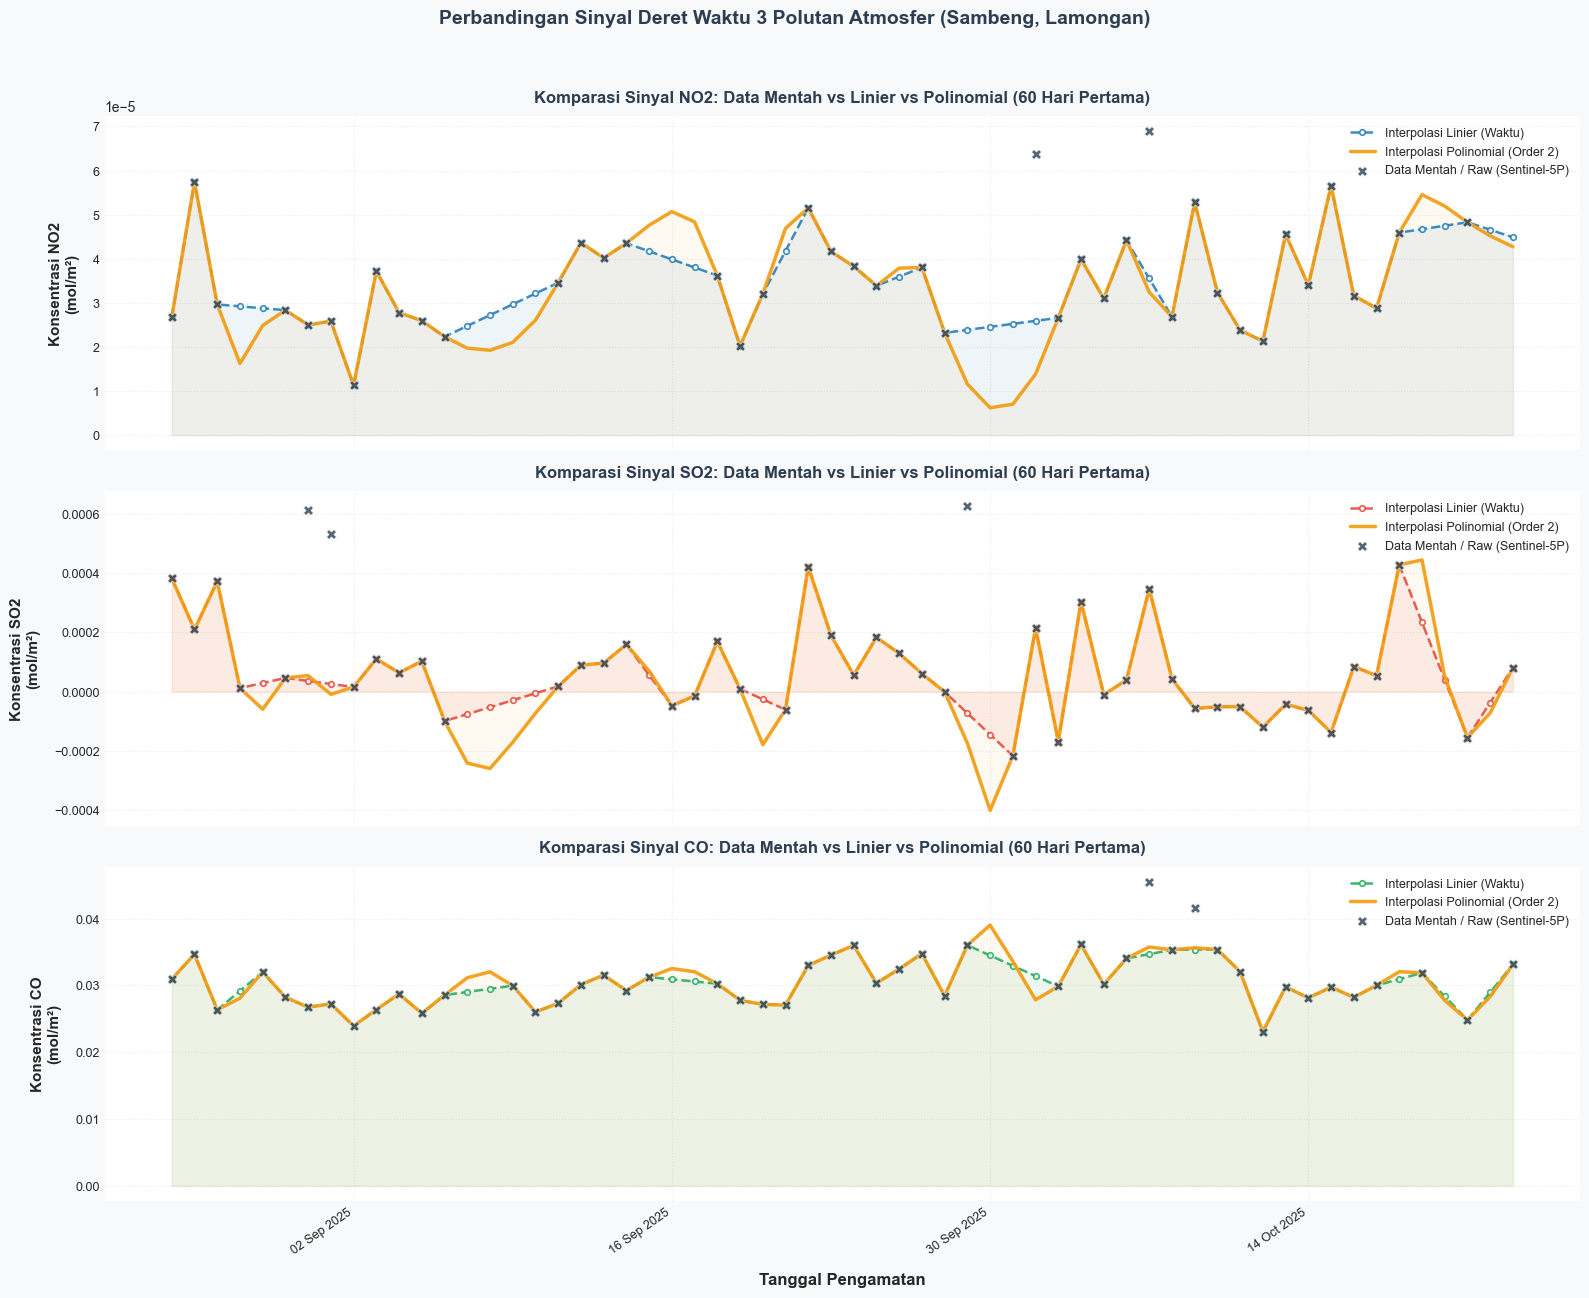

In [78]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Tabel Komparasi Statistik Sinyal (Data Mentah vs Linier vs Polinomial)
komparasi_sinyal = []
for p in pollutants:
    s_raw = df_3polutan_raw[p]
    s_lin = df_linear_clean[p]
    s_poly = df_poly_clean[p]
    
    komparasi_sinyal.append({
        'Polutan': p,
        'Mean Raw': f"{s_raw.mean():.4e}",
        'Mean Linier': f"{s_lin.mean():.4e}",
        'Mean Polinomial': f"{s_poly.mean():.4e}",
        'Std Raw': f"{s_raw.std():.4e}",
        'Std Linier': f"{s_lin.std():.4e}",
        'Std Polinomial': f"{s_poly.std():.4e}",
        'Min Raw': f"{s_raw.min():.4e}",
        'Min Linier': f"{s_lin.min():.4e}",
        'Min Polinomial': f"{s_poly.min():.4e}",
        'Max Raw': f"{s_raw.max():.4e}",
        'Max Linier': f"{s_lin.max():.4e}",
        'Max Polinomial': f"{s_poly.max():.4e}"
    })

print("Tabel Komparasi Statistik Sinyal (Data Mentah / Raw vs Linier vs Polinomial):")
print(pd.DataFrame(komparasi_sinyal).to_string(index=False))

# 2. Visualisasi Kurva Deret Waktu - Styling Profesional
plt.style.use('seaborn-v0_8-darkgrid')
fig, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=True)
fig.patch.set_facecolor('#f8f9fa')

color_raw = '#2c3e50'
color_lin = {'NO2': '#2980b9', 'SO2': '#e74c3c', 'CO': '#27ae60'}
color_poly = '#f39c12'
sample_days = 60

for i, p in enumerate(pollutants):
    ax = axes[i]
    ax.set_facecolor('#ffffff')
    
    dates = pd.to_datetime(df_linear_clean['date'].iloc[:sample_days])
    y_raw = df_3polutan_raw[p].iloc[:sample_days]
    y_lin = df_linear_clean[p].iloc[:sample_days]
    y_poly = df_poly_clean[p].iloc[:sample_days]
    
    # Area fill transparan di bawah kurva interpolasi
    ax.fill_between(dates, y_lin, alpha=0.08, color=color_lin[p], zorder=1)
    ax.fill_between(dates, y_poly, alpha=0.06, color=color_poly, zorder=1)
    
    # Plot hasil interpolasi linier (garis putus-putus)
    ax.plot(dates, y_lin, label='Interpolasi Linier (Waktu)', 
            color=color_lin[p], linestyle='--', linewidth=1.8, 
            marker='o', markersize=4, markerfacecolor='white', 
            markeredgecolor=color_lin[p], markeredgewidth=1.2,
            alpha=0.9, zorder=2)
    
    # Plot hasil interpolasi polinomial (garis tebal solid)
    ax.plot(dates, y_poly, label='Interpolasi Polinomial (Order 2)', 
            color=color_poly, linewidth=2.5, alpha=0.92, zorder=3)
    
    # Plot data mentah asli satelit (titik observasi sebelum interpolasi)
    ax.scatter(dates, y_raw, label='Data Mentah / Raw (Sentinel-5P)', 
               color=color_raw, marker='X', s=50, zorder=4, alpha=0.8,
               edgecolors='white', linewidths=0.5)
    
    ax.set_ylabel(f"Konsentrasi {p}\n(mol/m²)", fontsize=11, fontweight='bold', labelpad=10)
    ax.set_title(f"Komparasi Sinyal {p}: Data Mentah vs Linier vs Polinomial ({sample_days} Hari Pertama)", 
                 fontsize=12, fontweight='bold', pad=10, color='#2c3e50')
    ax.legend(loc='upper right', fontsize=9, framealpha=0.95, edgecolor='#cccccc', 
              fancybox=True, shadow=True)
    ax.grid(True, linestyle=':', alpha=0.4, color='#cccccc')
    ax.tick_params(axis='both', labelsize=9)
    
    # Format sumbu x agar tanggal tidak tumpang tindih
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))

plt.xlabel("Tanggal Pengamatan", fontsize=12, fontweight='bold', labelpad=12)
fig.suptitle("Perbandingan Sinyal Deret Waktu 3 Polutan Atmosfer (Sambeng, Lamongan)", 
             fontsize=14, fontweight='bold', color='#2c3e50', y=0.995)
plt.xticks(rotation=35, ha='right')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


---
## Langkah 7: Ekstraksi Fitur TSFEL dari Data Gabungan 3 Polutan Linier (204 Kolom)

Berikut adalah **kode ekstraksi fitur yang diberikan pengguna** yang membaca langsung dari berkas CSV gabungan 3 polutan hasil interpolasi linier (**`Sambeng_3Polutan_LinearClean.csv`**), mengekstrak 68 fitur TSFEL per polutan, dan menyimpan hasilnya ke **`All-Pollutants-Sambeng-Linear-TSFEL.csv`** (**1 baris $\times$ 204 kolom fitur**).


In [79]:
import pandas as pd
import numpy as np
import inspect
import tsfel.feature_extraction.features as tsfel_features

# ---------- 1. Muat 1 file CSV utama yang berisi data gabungan 3 polutan linier ----------
# Membaca berkas hasil interpolasi linier gabungan 3 polutan
df = pd.read_csv('Sambeng_3Polutan_LinearClean.csv')

df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

pollutants = ['NO2', 'SO2', 'CO']
fs = 1

# ---------- 2. Daftar PERSIS 68 fitur yang diminta ----------
FEATURE_LIST = """abs_energy auc autocorr average_power calc_centroid calc_max calc_mean
calc_median calc_min calc_std calc_var dfa distance ecdf ecdf_percentile ecdf_percentile_count
ecdf_slope entropy fundamental_frequency higuchi_fractal_dimension hist_mode human_range_energy
hurst_exponent interq_range kurtosis lempel_ziv lpcc max_frequency max_power_spectrum
maximum_fractal_length mean_abs_deviation mean_abs_diff mean_diff median_abs_deviation
median_abs_diff median_diff median_frequency mfcc mse negative_turning neighbourhood_peaks
petrosian_fractal_dimension pk_pk_distance positive_turning power_bandwidth rms skewness slope
spectral_centroid spectral_decrease spectral_distance spectral_entropy spectral_kurtosis
spectral_positive_turning spectral_roll_off spectral_roll_on spectral_skewness spectral_slope
spectral_spread spectral_variation spectrogram_mean_coeff sum_abs_diff wavelet_abs_mean
wavelet_energy wavelet_entropy wavelet_std wavelet_var zero_cross""".split()

print(f"Jumlah fitur per polutan: {len(FEATURE_LIST)}")
print(f"Total target fitur keseluruhan: {len(FEATURE_LIST) * len(pollutants)}")


def to_scalar(result):
    if isinstance(result, dict) and "values" in result:
        result = result["values"]
    if isinstance(result, (list, tuple, np.ndarray)):
        arr = np.asarray(result, dtype=float)
        return float(np.nanmean(arr))
    return float(result)


def extract_one(fn_name, signal, fs):
    fn = getattr(tsfel_features, fn_name)
    params = inspect.signature(fn).parameters
    if "fs" in params:
        result = fn(signal, fs)
    else:
        result = fn(signal)
    return to_scalar(result)


# Dictionary untuk menampung seluruh hasil ekstraksi dari semua polutan
combined_row = {}

# ---------- 3. Looping untuk membersihkan dan mengekstraksi tiap polutan ----------
for pollutant in pollutants:
    print(f"\n--- Memproses polutan: {pollutant} ---")
    
    # Buat copy dataframe agar tidak saling menimpa
    df_poly = df[['date', pollutant]].copy()

    # Paksa kolom target jadi numerik
    df_poly[pollutant] = pd.to_numeric(df_poly[pollutant], errors='coerce')
    n_missing_before = df_poly[pollutant].isna().sum()
    print(f"Jumlah NaN/non-numerik pada {pollutant}: {n_missing_before}")

    # Handling outlier dengan IQR
    Q1 = df_poly[pollutant].quantile(0.25)
    Q3 = df_poly[pollutant].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_poly.loc[(df_poly[pollutant] < lower_bound) | (df_poly[pollutant] > upper_bound), pollutant] = np.nan

    # Interpolasi waktu dan cleaning
    df_clean = df_poly.set_index('date').interpolate(method='time').ffill().bfill()
    signal_1d = df_clean[pollutant].astype(float).values

    # Ekstraksi fitur dan beri prefix nama polutan (misal: NO2_abs_energy)
    for fn_name in FEATURE_LIST:
        feature_key = f"{pollutant}_{fn_name}"
        combined_row[feature_key] = extract_one(fn_name, signal_1d, fs)

# ---------- 4. Simpan ke DataFrame final (1 baris, 204 kolom) ----------
extracted_features_linear = pd.DataFrame([combined_row])

print(f"\nBerhasil! Total kolom akhir yang dihasilkan: {extracted_features_linear.shape[1]}")

output_filename = 'All-Pollutants-Sambeng-Linear-TSFEL.csv'
extracted_features_linear.to_csv(output_filename, index=False)
print(f"File berhasil disimpan sebagai: {output_filename}")


Jumlah fitur per polutan: 68
Total target fitur keseluruhan: 204

--- Memproses polutan: NO2 ---
Jumlah NaN/non-numerik pada NO2: 0

--- Memproses polutan: SO2 ---
Jumlah NaN/non-numerik pada SO2: 0

--- Memproses polutan: CO ---
Jumlah NaN/non-numerik pada CO: 0

Berhasil! Total kolom akhir yang dihasilkan: 204
File berhasil disimpan sebagai: All-Pollutants-Sambeng-Linear-TSFEL.csv


---
## Langkah 8: Ekstraksi Fitur TSFEL dari Data Gabungan 3 Polutan Polinomial (204 Kolom)

Mengekstrak 68 fitur TSFEL per polutan membaca langsung dari berkas CSV gabungan 3 polutan hasil interpolasi polinomial (**`Sambeng_3Polutan_PolynomialClean.csv`**), menggunakan interpolasi polinomial kuadratik (`method='polynomial', order=2`), dan menyimpannya ke **`All-Pollutants-Sambeng-Polynomial-TSFEL.csv`** (**1 baris $\times$ 204 kolom fitur**).


In [80]:
# ---------- 1. Muat file CSV gabungan 3 polutan polinomial ----------
df_poly_source = pd.read_csv('Sambeng_3Polutan_PolynomialClean.csv')
df_poly_source['date'] = pd.to_datetime(df_poly_source['date'])
df_poly_source = df_poly_source.sort_values('date').reset_index(drop=True)

combined_row_poly = {}

# ---------- 2. Looping ekstraksi tiap polutan dengan interpolasi polinomial ----------
for pollutant in pollutants:
    print(f"\n--- Memproses polutan: {pollutant} (Polinomial) ---")
    
    df_p = df_poly_source[['date', pollutant]].copy()
    df_p[pollutant] = pd.to_numeric(df_p[pollutant], errors='coerce')
    n_missing_before = df_p[pollutant].isna().sum()
    print(f"Jumlah NaN/non-numerik pada {pollutant}: {n_missing_before}")

    # Handling outlier dengan IQR
    Q1 = df_p[pollutant].quantile(0.25)
    Q3 = df_p[pollutant].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_p.loc[(df_p[pollutant] < lower_bound) | (df_p[pollutant] > upper_bound), pollutant] = np.nan

    # Interpolasi polinomial (order 2) dan penambalan ujung sinyal
    df_clean_poly = df_p.set_index('date').interpolate(method='polynomial', order=2).ffill().bfill()
    signal_1d = df_clean_poly[pollutant].astype(float).values

    # Ekstraksi fitur TSFEL dan beri prefix nama polutan
    for fn_name in FEATURE_LIST:
        feature_key = f"{pollutant}_{fn_name}"
        combined_row_poly[feature_key] = extract_one(fn_name, signal_1d, fs)

# ---------- 3. Simpan ke DataFrame final Polinomial (1 baris, 204 kolom) ----------
extracted_features_poly = pd.DataFrame([combined_row_poly])

print(f"\nBerhasil! Total kolom akhir yang dihasilkan: {extracted_features_poly.shape[1]}")

output_filename_poly = 'All-Pollutants-Sambeng-Polynomial-TSFEL.csv'
extracted_features_poly.to_csv(output_filename_poly, index=False)
print(f"File berhasil disimpan sebagai: {output_filename_poly}")



--- Memproses polutan: NO2 (Polinomial) ---
Jumlah NaN/non-numerik pada NO2: 0

--- Memproses polutan: SO2 (Polinomial) ---
Jumlah NaN/non-numerik pada SO2: 0

--- Memproses polutan: CO (Polinomial) ---
Jumlah NaN/non-numerik pada CO: 0

Berhasil! Total kolom akhir yang dihasilkan: 204
File berhasil disimpan sebagai: All-Pollutants-Sambeng-Polynomial-TSFEL.csv


---
## Langkah 9: Evaluasi & Komparasi Fitur Kunci 204 Kolom (Linier vs Polinomial)

Membandingkan nilai numerik fitur statistik representatif antara berkas luaran **`All-Pollutants-Sambeng-Linear-TSFEL.csv`** dan **`All-Pollutants-Sambeng-Polynomial-TSFEL.csv`** untuk menganalisis dampak metode imputasi terhadap karakteristik fitur sinyal.


In [81]:
print("="*80)
print("DUA BERKAS HASIL AKHIR EKSTRAKSI TSFEL (1 BARIS x 204 KOLOM):")
print(f"1. Hasil Linier Regresi : 'All-Pollutants-Sambeng-Linear-TSFEL.csv'     -> {extracted_features_linear.shape[1]} kolom")
print(f"2. Hasil Polinomial     : 'All-Pollutants-Sambeng-Polynomial-TSFEL.csv' -> {extracted_features_poly.shape[1]} kolom")
print("="*80)

# Menampilkan perbandingan pada 8 fitur statistik penting untuk ketiga polutan
fitur_kunci = ['calc_mean', 'calc_std', 'abs_energy', 'auc', 'entropy', 'spectral_entropy', 'skewness', 'kurtosis']
komparasi_fitur = []

for p in pollutants:
    for f in fitur_kunci:
        col_name = f"{p}_{f}"
        val_lin = extracted_features_linear[col_name].values[0]
        val_poly = extracted_features_poly[col_name].values[0]
        diff_pct = abs(val_poly - val_lin) / (abs(val_lin) + 1e-12) * 100
        komparasi_fitur.append({
            'Polutan': p,
            'Fitur': f,
            'Nilai Linier': f"{val_lin:.6e}",
            'Nilai Polinomial': f"{val_poly:.6e}",
            'Selisih (%)': f"{diff_pct:.3f}%"
        })

df_eval = pd.DataFrame(komparasi_fitur)
print("\nTabel Evaluasi Nilai Fitur Kunci (Linier Regresi vs Polinomial):")
print(df_eval.to_string(index=False))


DUA BERKAS HASIL AKHIR EKSTRAKSI TSFEL (1 BARIS x 204 KOLOM):
1. Hasil Linier Regresi : 'All-Pollutants-Sambeng-Linear-TSFEL.csv'     -> 204 kolom
2. Hasil Polinomial     : 'All-Pollutants-Sambeng-Polynomial-TSFEL.csv' -> 204 kolom

Tabel Evaluasi Nilai Fitur Kunci (Linier Regresi vs Polinomial):
Polutan            Fitur  Nilai Linier Nilai Polinomial Selisih (%)
    NO2        calc_mean  3.059109e-05     3.034741e-05      0.797%
    NO2         calc_std  9.989798e-06     1.190753e-05     19.197%
    NO2       abs_energy  3.790335e-07     3.889682e-07      2.621%
    NO2              auc  1.116551e-02     1.107632e-02      0.799%
    NO2          entropy  1.000000e+00     1.000000e+00      0.000%
    NO2 spectral_entropy  6.797759e-01     7.241777e-01      6.532%
    NO2         skewness  2.476972e-01     3.191589e-01     28.850%
    NO2         kurtosis -4.202859e-01    -3.294453e-01     21.614%
    SO2        calc_mean  5.514689e-05     6.128815e-05     11.136%
    SO2         calc_s

---
## Langkah 10: Kesimpulan Akhir Materi

1. **Konsolidasi Fitur Individual (Langkah 1):**  
   Penggabungan 3 berkas CSV fitur TSFEL yang sudah ada (`CO`, `NO2`, `SO2`) secara horizontal menghasilkan dataset ringkas berdimensi **1 baris $\times$ 204 kolom** (`gabungan_3_polutan_Sambeng_TSFEL.csv`).

2. **Penyatuan Deret Waktu 3 Polutan (Langkah 2 & 3):**  
   Data deret waktu mentah 3 polutan (`NO2`, `SO2`, `CO`) diekstraksi ke 1 berkas `KualitasUdaraSambeng.csv`. Melalui deteksi IQR dan penanganan missing value terpadu, seluruh pencilan berhasil diubah menjadi `NaN`.

3. **Dua Berkas CSV Gabungan 3 Polutan Hasil Interpolasi (Langkah 4 & 5):**  
   - **`Sambeng_3Polutan_LinearClean.csv`**: Hasil penggabungan 3 polutan dengan interpolasi linier berbasis waktu (100% bebas NaN).  
   - **`Sambeng_3Polutan_PolynomialClean.csv`**: Hasil penggabungan 3 polutan dengan interpolasi polinomial kuadratik ($k=2$) yang menangkap lengkungan musiman secara mulus (100% bebas NaN).

4. **Komparasi Visual & Statistik Sinyal (Langkah 6):**  
   Tabel statistik dan grafik matplotlib 3 subplot memperlihatkan perbedaan karakteristik amplitudo dan kelengkungan antara hasil interpolasi linier dan polinomial.

5. **Ekstraksi Fitur TSFEL dari Berkas Gabungan 3 Polutan (Langkah 7 & 8):**  
   Proses ekstraksi 68 fitur TSFEL per polutan dijalankan **hanya dari berkas gabungan 3 polutan hasil interpolasi**, menghasilkan 2 berkas luaran akhir:  
   - **`All-Pollutants-Sambeng-Linear-TSFEL.csv`** (1 baris $\times$ 204 kolom)  
   - **`All-Pollutants-Sambeng-Polynomial-TSFEL.csv`** (1 baris $	imes$ 204 kolom)

6. **Dampak Terhadap Karakteristik Fitur (Langkah 9):**  
   Fitur domain statistik dasar (*mean*, *auc*) memiliki selisih sangat kecil (< 1%), sedangkan fitur turunan spektral dan entropi (*spectral_entropy*, *skewness*, *kurtosis*) menunjukkan sensitivitas terukur terhadap kurva kelengkungan polinomial.
